In [1]:
import warnings
warnings.filterwarnings('ignore')   # keep the notebook output readable

import glob
import logging
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray  # noqa: F401, activates the .rio accessor
import xarray as xr
from pyproj import Transformer
from scipy import ndimage

import GRSl2bgen

logging.getLogger().setLevel(logging.WARNING)

# lighter figures for the documentation
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams.update({'figure.dpi': 72, 'font.size': 12, 'axes.titlesize': 12})

print(f'GRSl2bgen {GRSl2bgen.__version__}')

GRSl2bgen 1.2.0dev0


In [2]:
L2A_DIR = '/data/satellite/Sentinel-2/L2A_zarr'
TILE = '31TFJ'
LAKE = 'Étang de Berre'
LON, LAT = 5.11, 43.47                # centre of the lagoon
WIDTH, HEIGHT = 22000, 22000          # box around the lagoon (m)
MIN_LAKE_FRACTION = 0.5               # minimum proportion of valid lagoon pixels
CACHE = f'/data/satellite/Sentinel-2/datacube/{TILE}_berre_L2B_GRSl2bgen-{GRSl2bgen.__version__}.nc'

GROUPS = {
    'Kd(490)': ['Kd490_Lee13', 'Kd490_KD2'],
    'Kd(PAR)': ['Kd_par_Lee05', 'Kd_par_Mo07', 'Kd_par'],
    'Depths': ['Zeu_Lee05', 'Zsd_Lee15'],
}
NEW = ['Kd490_Lee13', 'Kd490_KD2', 'Kd_par_Mo07', 'Zeu_Lee05', 'Kd_par_Lee05']
CONSTITUENTS = ['Chla_OWTblend_Ta2025', 'SPM_OWTblend_Ta2025', 'TURB_dogliotti', 'adg443_QAAv6']
PARAMS = [param for params in GROUPS.values() for param in params]
KEEP = PARAMS + CONSTITUENTS + ['owt_index_Bi2024', 'owt_dist_Bi2024', 'flags', 'flags_l2b', 'mask']

In [3]:
paths = sorted(glob.glob(os.path.join(L2A_DIR, TILE, '*', '*', '*', '*', '*.zarr')))
products = pd.DataFrame({'path': paths})
products['name'] = products.path.map(os.path.basename)
products['time'] = pd.to_datetime(products.name.str.extract(r'_(\d{8}T\d{6})_N', expand=False))
products['orbit'] = products.name.str.extract(r'_(R\d{3})_', expand=False)
products = products.sort_values('time').reset_index(drop=True)
print(f'{len(products)} L2A products from {products.time.min():%Y-%m-%d} to {products.time.max():%Y-%m-%d}')
products.groupby('orbit').time.agg(['count', 'min', 'max'])

54 L2A products from 2021-02-11 to 2021-08-30


,count,min,max
orbit,,,
R008,29,2021-02-11 10:41:51,2021-08-30 10:40:21
R108,25,2021-02-13 10:30:39,2021-08-27 10:30:21


In [4]:
x0, y0 = Transformer.from_crs(4326, 32631, always_xy=True).transform(LON, LAT)
box = dict(x=slice(x0 - WIDTH / 2, x0 + WIDTH / 2), y=slice(y0 + HEIGHT / 2, y0 - HEIGHT / 2))


def open_box(path):
    # full-resolution level of the L2A pyramid, cropped to the box
    return xr.open_zarr(path, group='0').sel(**box)


coverage = {}
for orbit, group in products.groupby('orbit'):
    sample = group.path.iloc[np.linspace(0, len(group) - 1, 4).astype(int)]
    coverage[orbit] = [int((open_box(path).mask == 0).sum()) for path in sample]
coverage = pd.DataFrame(coverage, index=[f'product {i + 1}' for i in range(4)])
print('valid water pixels in the box:')
coverage

valid water pixels in the box:


,R008,R108
product 1,443810,434912
product 2,417416,437992
product 3,423930,438508
product 4,436610,437530


In [5]:
def l2b_box(path):
    # GRSl2bgen chain on the box of one L2A image; None if no valid water pixel
    img = open_box(path).load()
    if not (img.mask == 0).any():
        return None
    img.attrs = dict(img.attrs)   # the L2B product updates the attributes in place
    proc = GRSl2bgen.Process(img)
    proc.execute()
    l2b = proc.l2b.l2b_prod[KEEP].compute()
    return l2b.map(lambda v: v.astype('float32') if v.dtype == 'float64' else v, keep_attrs=True)


def netcdf_safe(attrs):
    # NetCDF has no boolean attribute type
    return {k: (int(v) if isinstance(v, (bool, np.bool_)) else v) for k, v in attrs.items()}


if not os.path.exists(CACHE):
    t0 = time.time()
    images = [l2b for l2b in map(l2b_box, products.path) if l2b is not None]
    # variable attributes (units, range, flag_names...) from the first image
    l2b = xr.concat(images, 'time', coords='minimal', compat='override', combine_attrs='override')
    l2b.attrs = {'processor': f'GRSl2bgen_{GRSl2bgen.__version__}', 'tile': TILE,
                 'box': f'{WIDTH} x {HEIGHT} m around ({LON}, {LAT})'}
    for var in l2b.variables.values():
        var.attrs = netcdf_safe(var.attrs)
    encoding = {v: {'zlib': True, 'complevel': 4} for v in l2b.data_vars}
    l2b.to_netcdf(CACHE, encoding=encoding)
    print(f'{len(images)} images processed in {time.time() - t0:.0f} s')
    del images

l2b = xr.open_dataset(CACHE, decode_coords='all').load()
print(f"{l2b.sizes['time']} images, {l2b.sizes['y']} x {l2b.sizes['x']} pixels, {l2b.rio.crs}, "
      f'{l2b.nbytes / 1e9:.1f} GB')
l2b

54 images, 1100 x 1100 pixels, EPSG:32631, 4.0 GB


<xarray.Dataset> Size: 4GB
Dimensions:               (time: 54, y: 1100, x: 1100)
Coordinates:
  * time                  (time) datetime64[ns] 432B 2021-02-11T10:41:51 ... ...
  * y                     (y) float64 9kB 4.826e+06 4.826e+06 ... 4.804e+06
  * x                     (x) float64 9kB 6.597e+05 6.597e+05 ... 6.816e+05
    spatial_ref           int32 4B 0
Data variables: (12/16)
    Kd490_Lee13           (time, y, x) float32 261MB nan nan nan ... nan nan nan
    Kd490_KD2             (time, y, x) float32 261MB nan nan nan ... nan nan nan
    Kd_par_Lee05          (time, y, x) float32 261MB nan nan nan ... nan nan nan
    Kd_par_Mo07           (time, y, x) float32 261MB nan nan nan ... nan nan nan
    Kd_par                (time, y, x) float32 261MB nan nan nan ... nan nan nan
    Zeu_Lee05             (time, y, x) float32 261MB nan nan nan ... nan nan nan
    ...                    ...
    adg443_QAAv6          (time, y, x) float32 261MB nan nan nan ... nan nan nan
    owt_index_Bi2024      (time, y, x) float32 261MB nan nan nan ... nan nan nan
    owt_dist_Bi2024       (time, y, x) float32 261MB nan nan nan ... nan nan nan
    flags                 (time, y, x) uint32 261MB 512 512 512 ... 512 512 512
    flags_l2b             (time, y, x) uint32 261MB 0 0 0 0 0 0 ... 0 0 0 0 0 0
    mask                  (time, y, x) uint8 65MB 1 1 1 1 1 1 1 ... 1 1 1 1 1 1
Attributes:
    processor:  GRSl2bgen_1.2.0dev0
    tile:       31TFJ
    box:        22000 x 22000 m around (5.11, 43.47)

In [6]:
def label(param):
    return f"{param} ({l2b[param].attrs.get('units', '')})"


inventory = pd.DataFrame({param: {key: l2b[param].attrs.get(key, '')
                                  for key in ['units', 'range', 'applicability', 'description']}
                          for param in PARAMS}).T
with pd.option_context('display.max_colwidth', 120):
    display(inventory)

,units,range,applicability,description
Kd490_Lee13,m-1,"[0, 50]",optically deep waters,Diffuse attenuation coefficient at 490 nm from QAA v6 inherent optical properties and the model of Lee et al. (2013)...
Kd490_KD2,m-1,"[0, 50]",open ocean (Case 1) waters,"Diffuse attenuation coefficient at 490 nm, empirical blue/green band ratio polynomial (NASA KD2, MERIS KD2E coeffici..."
Kd_par_Lee05,m-1,"[0, 50]",optically deep waters,"Diffuse attenuation coefficient of PAR averaged over the euphotic zone, ln(100) / Zeu_Lee05"
Kd_par_Mo07,m-1,"[0, 50]",open ocean (Case 1) waters,"Diffuse attenuation coefficient of PAR over the first optical depth, from Kd490_Lee13"
Kd_par,m-1,"[0, 3000]",general,Coefficient of diffuse attenuation of PAR
Zeu_Lee05,m,"[0, 200]",optically deep waters,"Euphotic depth, depth of 1 % of the surface PAR, from QAA v6 a(490) and bb(490)"
Zsd_Lee15,m,"[0, 100]",optically deep waters,Secchi disk depth from the diffuse attenuation coefficient and Rrs at the most transparent band (443-665 nm); Kd fro...


lagoon: 386455 pixels (155 km²); 50 images out of 54 kept


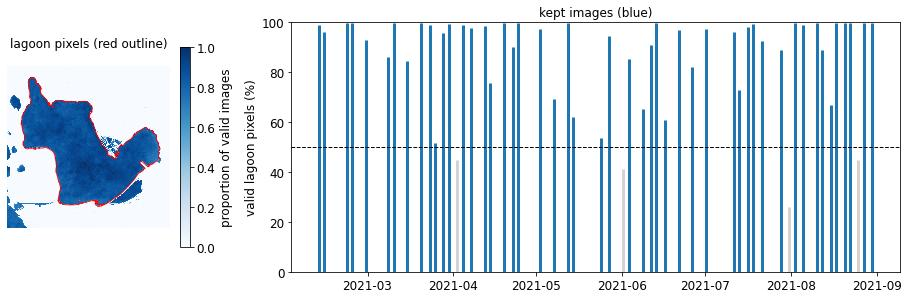

In [7]:
valid = (l2b.mask == 0) & l2b['Kd490_Lee13'].notnull()
frequent = valid.mean('time') >= 0.3
components, _ = ndimage.label(frequent.values)
lake = frequent.copy(data=components == np.bincount(components.ravel())[1:].argmax() + 1)
lake_fraction = valid.where(lake).sum(['x', 'y']) / lake.sum()
good = lake_fraction >= MIN_LAKE_FRACTION
cube = l2b.where(valid & lake).sel(time=good)
pixel_area = abs(np.prod(l2b.rio.resolution())) / 1e6
print(f'lagoon: {int(lake.sum())} pixels ({lake.sum().values * pixel_area:.0f} km²); '
      f'{int(good.sum())} images out of {l2b.sizes["time"]} kept')

fig, axs = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 3]})
valid.mean('time').plot.imshow(ax=axs[0], cmap='Blues', vmin=0, vmax=1, add_labels=False,
                               cbar_kwargs={'label': 'proportion of valid images', 'shrink': 0.8})
lake.plot.contour(ax=axs[0], levels=[0.5], colors='r', linewidths=0.8, add_labels=False)
axs[0].set_aspect('equal')
axs[0].set_axis_off()
axs[0].set_title('lagoon pixels (red outline)')
axs[1].vlines(lake_fraction.time.values, 0, lake_fraction * 100, lw=3,
              colors=np.where(good, 'tab:blue', 'lightgrey'))
axs[1].axhline(MIN_LAKE_FRACTION * 100, c='k', ls='--', lw=1)
axs[1].set_ylabel('valid lagoon pixels (%)')
axs[1].set_ylim(0, 100)
axs[1].set_title('kept images (blue)')
plt.show()

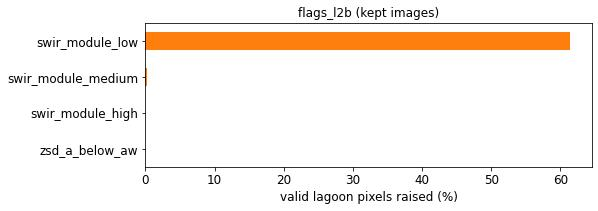

In [8]:
def flag_names(var):
    names = var.attrs['flag_names']
    return list(names) if not isinstance(names, str) else names.split()


kept_valid = (valid & lake).sel(time=good)
bits = l2b.flags_l2b.sel(time=good).where(kept_valid).values
bits = bits[np.isfinite(bits)].astype(np.uint32)
freq_l2b = pd.Series({name: ((bits >> i) & 1).mean() * 100
                      for i, name in enumerate(flag_names(l2b.flags_l2b)) if name != 'None'})
freq_l2b = freq_l2b[freq_l2b > 0]
ax = freq_l2b.plot.barh(color='tab:orange', figsize=(8, 0.4 * len(freq_l2b) + 1))
ax.invert_yaxis()
ax.set_xlabel('valid lagoon pixels raised (%)')
ax.set_title('flags_l2b (kept images)')
plt.show()

In [9]:
stats = {param: cube[param].quantile([0.25, 0.5, 0.75], ['x', 'y']).to_pandas().T for param in PARAMS + CONSTITUENTS}
medians = pd.DataFrame({param: stats[param][0.5] for param in PARAMS + CONSTITUENTS})


def plot_median_iqr(params):
    quartiles = {param: cube[param].quantile([0.25, 0.5, 0.75], 'time') for param in params}
    medians_map = xr.concat([quartiles[p].sel(quantile=0.5) for p in params], 'p')
    vmin, vmax = np.nanpercentile(medians_map, [2, 98])
    iqr_max = np.nanpercentile([q.sel(quantile=0.75) - q.sel(quantile=0.25) for q in quartiles.values()], 98)
    fig, axs = plt.subplots(2, len(params), figsize=(4.6 * len(params), 8.2), squeeze=False)
    for col, param in enumerate(params):
        q = quartiles[param]
        q.sel(quantile=0.5).plot.imshow(ax=axs[0, col], cmap='Spectral_r', vmin=vmin, vmax=vmax,
                                        add_labels=False, cbar_kwargs={'label': label(param), 'shrink': 0.8})
        (q.sel(quantile=0.75) - q.sel(quantile=0.25)).plot.imshow(
            ax=axs[1, col], cmap='magma', vmin=0, vmax=iqr_max, add_labels=False,
            cbar_kwargs={'label': 'inter-quartile range', 'shrink': 0.8})
        axs[0, col].set_title(f'{param}: median', fontsize=10)
        axs[1, col].set_title(f'{param}: inter-quartile range', fontsize=10)
    for ax in axs.ravel():
        ax.set_axis_off()
        ax.set_aspect('equal')
    fig.tight_layout()
    plt.show()


def plot_series(params):
    fig, ax = plt.subplots(figsize=(15, 4))
    for i, param in enumerate(params):
        q = stats[param]
        ax.errorbar(q.index + pd.Timedelta(hours=8 * i), q[0.5], yerr=[q[0.5] - q[0.25], q[0.75] - q[0.5]],
                    fmt='o', ms=4, capsize=2, lw=1, label=param)
    ax.set_ylabel(f"lagoon median ({l2b[params[0]].attrs.get('units', '')})")
    ax.grid(alpha=0.3)
    ax.legend(ncols=len(params))
    plt.show()


def plot_density(params, n=300_000):
    ref = cube[params[0]].values.ravel()
    fig, axs = plt.subplots(1, len(params) - 1, figsize=(5.2 * (len(params) - 1), 4.6), squeeze=False)
    rng = np.random.default_rng(0)
    for ax, param in zip(axs[0], params[1:]):
        other = cube[param].values.ravel()
        ok = np.flatnonzero(np.isfinite(ref) & np.isfinite(other) & (ref > 0) & (other > 0))
        ok = rng.choice(ok, min(n, ok.size), replace=False)
        hb = ax.hexbin(ref[ok], other[ok], xscale='log', yscale='log', bins='log', gridsize=70, cmap='viridis',
                       mincnt=1)
        lims = np.nanpercentile(np.r_[ref[ok], other[ok]], [0.1, 99.9])
        if l2b[param].attrs.get('units') == l2b[params[0]].attrs.get('units'):
            ax.plot(lims, lims, 'k--', lw=1)
        rho = pd.Series(ref[ok]).corr(pd.Series(other[ok]), method='spearman')
        ax.set(xlabel=label(params[0]), ylabel=label(param), title=rf'Spearman $\rho$ = {rho:.2f}')
        fig.colorbar(hb, ax=ax, label='pixels (log)')
    fig.tight_layout()
    plt.show()


def describe(params):
    return pd.DataFrame({p: medians[p].describe(percentiles=[0.05, 0.5, 0.95]) for p in params}).T \
        .drop(columns='count').round(3)

,mean,std,min,5%,50%,95%,max
Kd490_Lee13,0.586,0.245,0.212,0.252,0.562,1.053,1.065
Kd490_KD2,0.289,0.130,0.155,0.165,0.249,0.459,0.923


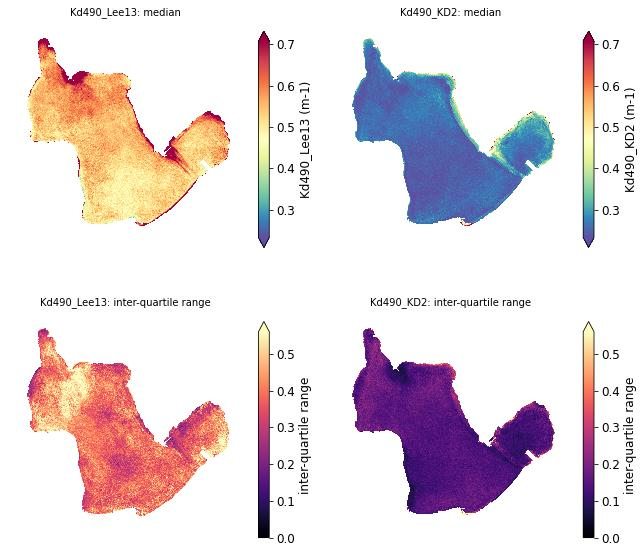

In [10]:
params = GROUPS['Kd(490)']
display(describe(params))
plot_median_iqr(params)

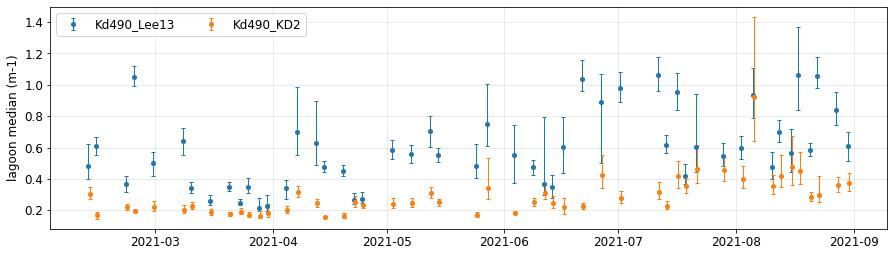

In [11]:
plot_series(params)

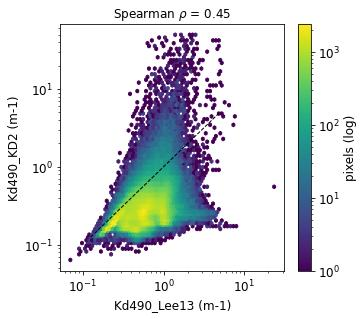

In [12]:
plot_density(params)

,mean,std,min,5%,50%,95%,max
Kd_par_Lee05,0.517,0.170,0.243,0.277,0.509,0.831,0.906
Kd_par_Mo07,0.602,0.218,0.268,0.304,0.580,1.016,1.026
Kd_par,2.331,0.390,1.406,1.683,2.303,2.928,3.060


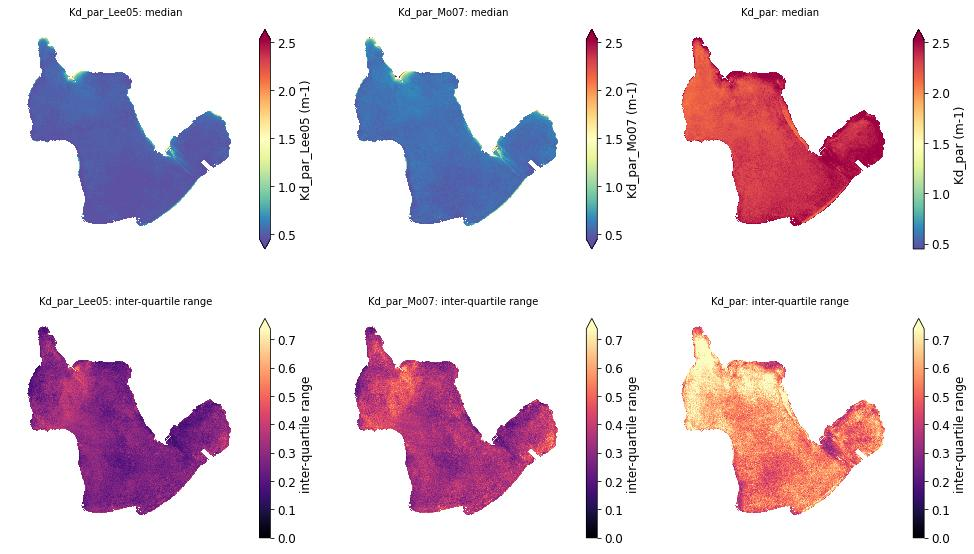

In [13]:
params = GROUPS['Kd(PAR)']
display(describe(params))
plot_median_iqr(params)

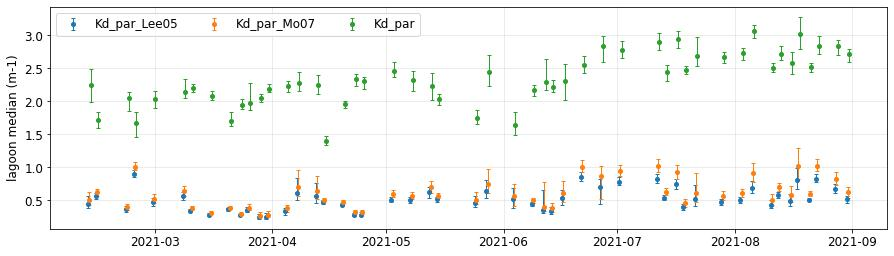

In [14]:
plot_series(params)

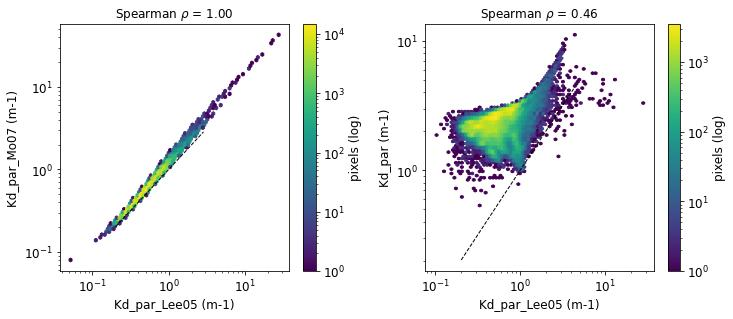

In [15]:
plot_density(params)

,mean,std,min,5%,50%,95%,max
Zeu_Lee05,9.942,3.480,5.085,5.543,9.054,16.625,18.929
Zsd_Lee15,2.577,1.092,1.020,1.246,2.281,4.803,5.281


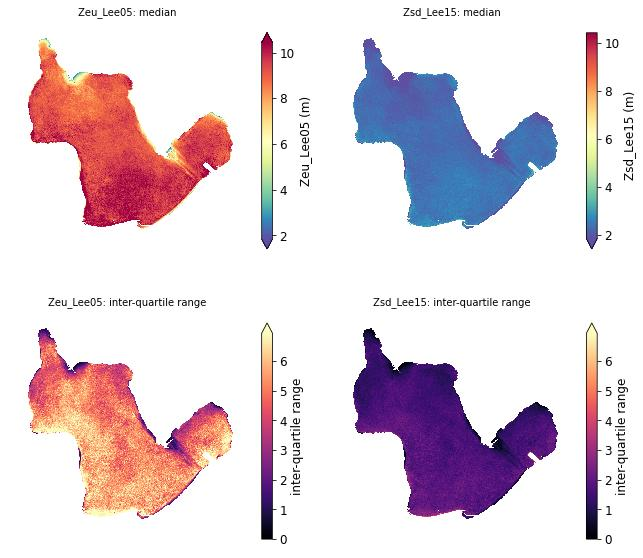

In [16]:
params = GROUPS['Depths']
display(describe(params))
plot_median_iqr(params)

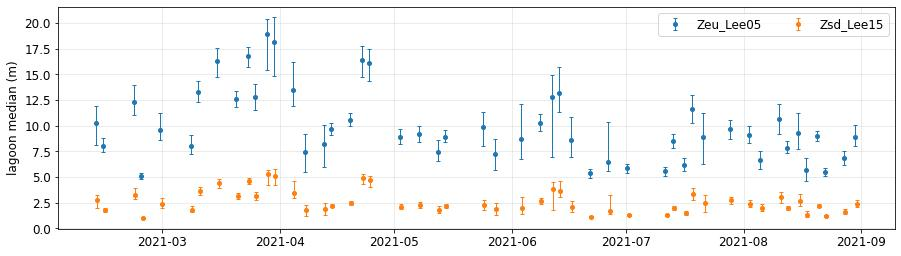

In [17]:
plot_series(params)

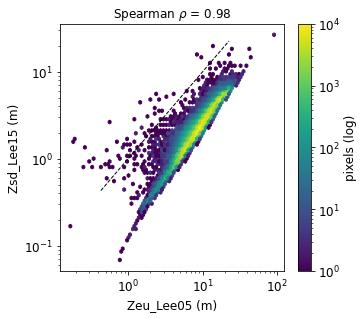

In [18]:
plot_density(params)

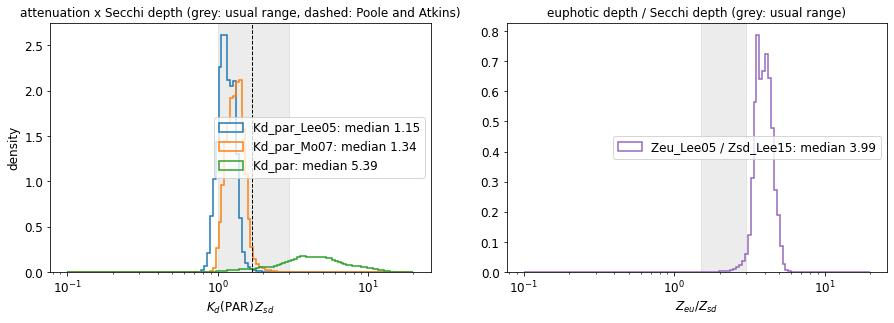

,median,p5,p95
Kd_par_Lee05 x Zsd_Lee15,1.15,0.94,1.41
Kd_par_Mo07 x Zsd_Lee15,1.34,1.07,1.67
Kd_par x Zsd_Lee15,5.39,2.32,11.37
Zeu_Lee05 / Zsd_Lee15,3.99,3.27,4.90


In [19]:
zsd = cube['Zsd_Lee15']
products_kz = {param: (cube[param] * zsd).values.ravel() for param in GROUPS['Kd(PAR)']}
ratio = (cube['Zeu_Lee05'] / zsd).values.ravel()

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
bins = np.logspace(-1, 1.3, 120)
for param, values in products_kz.items():
    values = values[np.isfinite(values)]
    axs[0].hist(values, bins=bins, histtype='step', lw=1.5, density=True,
                label=f'{param}: median {np.median(values):.2f}')
axs[0].axvspan(1, 3, color='grey', alpha=0.15)
axs[0].axvline(1.7, c='k', ls='--', lw=1)
axs[0].set(xscale='log', xlabel=r'$K_d(\mathrm{PAR})\, Z_{sd}$', ylabel='density',
           title='attenuation x Secchi depth (grey: usual range, dashed: Poole and Atkins)')
axs[0].legend()
values = ratio[np.isfinite(ratio)]
axs[1].hist(values, bins=bins, histtype='step', lw=1.5, density=True, color='tab:purple',
            label=f'Zeu_Lee05 / Zsd_Lee15: median {np.median(values):.2f}')
axs[1].axvspan(1.5, 3, color='grey', alpha=0.15)
axs[1].set(xscale='log', xlabel=r'$Z_{eu} / Z_{sd}$', title='euphotic depth / Secchi depth (grey: usual range)')
axs[1].legend()
plt.show()

consistency = pd.DataFrame({
    'median': [np.nanmedian(v) for v in products_kz.values()] + [np.nanmedian(ratio)],
    'p5': [np.nanpercentile(v, 5) for v in products_kz.values()] + [np.nanpercentile(ratio, 5)],
    'p95': [np.nanpercentile(v, 95) for v in products_kz.values()] + [np.nanpercentile(ratio, 95)],
}, index=[f'{p} x Zsd_Lee15' for p in products_kz] + ['Zeu_Lee05 / Zsd_Lee15'])
consistency.round(2)

In [20]:
n_valid = int(kept_valid.sum())
summary = pd.DataFrame({
    'units': [l2b[p].attrs.get('units', '') for p in PARAMS],
    'median': medians[PARAMS].median(),
    'p5': medians[PARAMS].quantile(0.05),
    'p95': medians[PARAMS].quantile(0.95),
    'CV (%)': medians[PARAMS].std() / medians[PARAMS].mean() * 100,
    'pixels with a value (%)': [int(cube[p].count()) / n_valid * 100 for p in PARAMS],
}, index=PARAMS)
summary.style.format({'median': '{:.3g}', 'p5': '{:.3g}', 'p95': '{:.3g}', 'CV (%)': '{:.0f}',
                      'pixels with a value (%)': '{:.1f}'})

,units,median,p5,p95,CV (%),pixels with a value (%)
Kd490_Lee13,m-1,0.562,0.252,1.05,42,100.0
Kd490_KD2,m-1,0.249,0.165,0.459,45,99.9
Kd_par_Lee05,m-1,0.509,0.277,0.831,33,100.0
Kd_par_Mo07,m-1,0.58,0.304,1.02,36,100.0
Kd_par,m-1,2.3,1.68,2.93,17,100.0
Zeu_Lee05,m,9.05,5.54,16.6,35,100.0
Zsd_Lee15,m,2.28,1.25,4.8,42,100.0


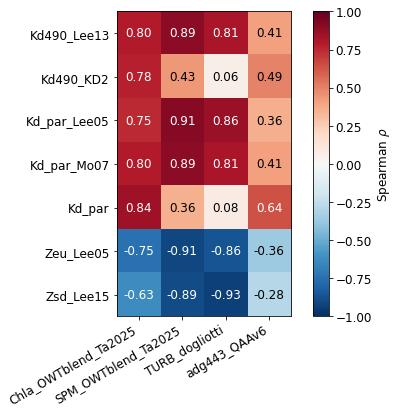

In [21]:
corr = medians.corr(method='spearman').loc[PARAMS, CONSTITUENTS]
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(CONSTITUENTS)), CONSTITUENTS, rotation=30, ha='right')
ax.set_yticks(range(len(PARAMS)), PARAMS)
for i in range(len(PARAMS)):
    for j in range(len(CONSTITUENTS)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='w' if abs(corr.iloc[i, j]) > 0.6 else 'k')
fig.colorbar(im, ax=ax, label=r'Spearman $\rho$')
plt.show()

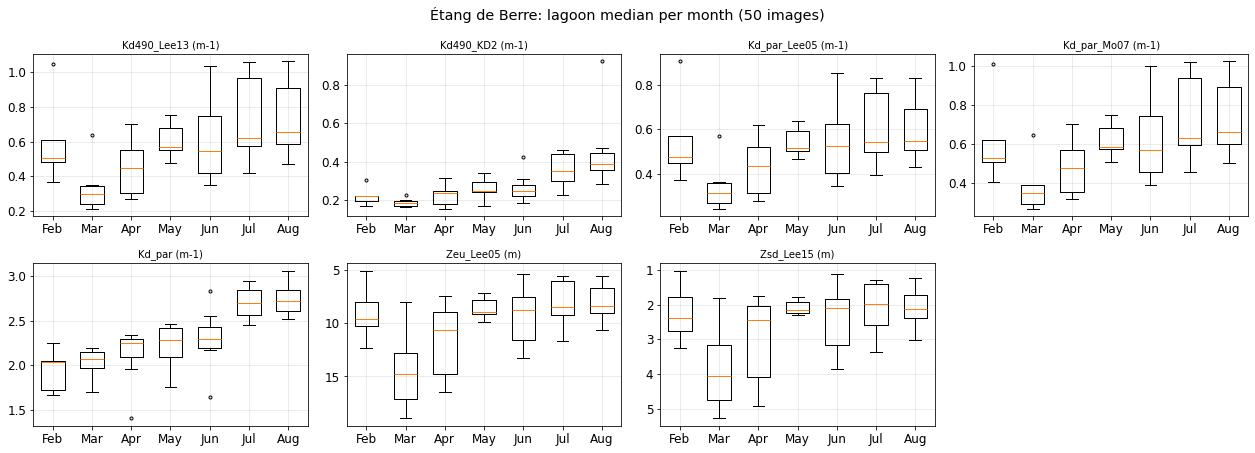

In [22]:
ncols = 4
nrows = int(np.ceil(len(PARAMS) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.2 * nrows))
months = sorted(medians.index.month.unique())
for ax, param in zip(axs.ravel(), PARAMS):
    values = [medians[param][medians.index.month == m].dropna() for m in months]
    ax.boxplot(values, positions=months, widths=0.6, flierprops={'markersize': 3})
    ax.set_xticks(months, [pd.Timestamp(2021, m, 1).strftime('%b') for m in months])
    ax.set_title(label(param), fontsize=10)
    ax.grid(alpha=0.3)
    if param.startswith('Z'):
        ax.invert_yaxis()
for ax in axs.ravel()[len(PARAMS):]:
    ax.set_visible(False)
fig.suptitle(f'{LAKE}: lagoon median per month ({len(medians)} images)')
fig.tight_layout()
plt.show()